In [1]:
import numpy as np
import juliacall
import komamripy as km


km.load_cuda() # GPU backend selection, optional

sys = km.Scanner()  # scanner hardware
obj = km.brain_phantom2D()  # 2D brain phantom
seq = km.PulseDesigner.EPI_example()  # example EPI sequence

sim_params = {"return_type": "mat"}  # return the raw signal matrix
raw = km.simulate(obj, seq, sys, sim_params=sim_params)

print(np.shape(raw))

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


Precompiling packages...
   6288.3 ms  ✓ MRIFiles
   8047.0 ms  ✓ KomaMRIBase → KomaMRIBaseUnitfulExt
  12020.4 ms  ✓ KomaMRIPlots
  36646.6 ms  ✓ KomaMRIFiles
  59659.1 ms  ✓ KomaMRI
  5 dependencies successfully precompiled in 130 seconds. 252 already precompiled.
[ Info: Using  backend: 'CUDA'
┌ Info: Running simulation in the GPU (NVIDIA GeForce RTX 3050 Laptop GPU — Device 0)
│   koma_version = v"0.14.0"
│   sim_method = Bloch()
│   spins = 6506
│   time_points = 10624
└   adc_points = 10201
Running simulation...   9%|███                          |  ETA: 0:10:33
   simulated_blocks: 2
          rf_blocks: 1
     acq_samples: 0


Running simulation...  13%|████                         |  ETA: 0:07:02
   simulated_blocks: 3
          rf_blocks: 1
     acq_samples: 492


Running simulation... 100%|█████████████████████████████| Time: 0:01:03
   simulated_blocks: 23
          rf_blocks: 1
        acq_samples: 10201


(10201, 1, 1)
 63.046950 seconds (45.36 M allocations: 2.998 GiB, 3.19% gc time, 95.07% compilation time: 2% of which was recompilation)


In [2]:
print(sys)

Scanner{LinearXYZ, UniformCoilSens, UniformTransmit}(HardwareLimits
  B0: Float64 1.5
  B1: Float64 1.0e-5
  Gmax: Float64 0.06
  Smax: Float64 500.0
  ADC_Δt: Float64 2.0e-6
  DUR_Δt: Float64 1.0e-5
  GR_Δt: Float64 1.0e-5
  RF_Δt: Float64 1.0e-6
  RF_ring_down_time: Float64 2.0e-5
  RF_dead_time: Float64 0.0001
  ADC_dead_time: Float64 1.0e-5
, LinearXYZ(), UniformCoilSens(), UniformTransmit())


c:\Users\royya\Desktop\ee290\final_project\EE-290-EPTI-Pulseq-Final-Project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
┌ Info: Running simulation in the GPU (NVIDIA GeForce RTX 3050 Laptop GPU — Device 0)
│   koma_version = v"0.14.0"
│   sim_method = Bloch()
│   spins = 6506
│   time_points = 10624
└   adc_points = 10201
Running simulation...   9%|███                          |  ETA: 0:00:01
   simulated_blocks: 2
          rf_blocks: 1
     acq_samples: 0


Running simulation... 100%|█████████████████████████████| Time: 0:00:00
   simulated_blocks: 23
          rf_blocks: 1
        acq_samples: 10201


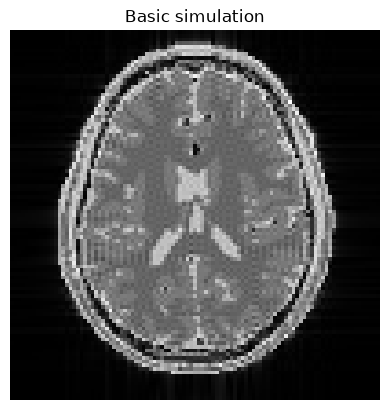

  0.227522 seconds (10.64 k allocations: 508.547 KiB)


In [3]:
"""Simulate a built-in EPI acquisition and reconstruct it with SigPy."""

import matplotlib.pyplot as plt
import numpy as np
import sigpy as sp

import komamripy as km

# Define acquisition inputs
sys = km.Scanner()
obj = km.brain_phantom2D()
obj.Δw = np.zeros_like(obj.Δw)  # removes fat off-resonance
seq = km.PulseDesigner.EPI_example()

# Simulate with KomaMRI
sim_params = {"return_type": "mat"}
signal = km.simulate(obj, seq, sys, sim_params=sim_params)
signal = np.asarray(signal).reshape(-1)

# Reconstruct with SigPy
matrix_size = int(np.sqrt(signal.size))
kdata = signal.reshape(matrix_size, matrix_size)
kdata[1::2] = kdata[1::2, ::-1]
image = sp.ifft(kdata, axes=(0, 1))

# Show the reconstructed image
plt.imshow(np.abs(image), cmap="gray", origin="lower")
plt.title("Basic simulation")
plt.axis("off")
plt.show()